CELL 1 — Import thư viện

In [21]:
# %%
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.io import wavfile
from pydub import AudioSegment
import imageio_ffmpeg

print("Các thư viện đã được import thành công.")

Các thư viện đã được import thành công.


CELL 2 — Cấu hình đường dẫn

In [22]:
# %%
# ==============================
# CẤU HÌNH
# ==============================

INPUT_FILE = "input.mp3"

AUDIO_DIR = "audio"
FIGURE_DIR = "figures"
RESULT_DIR = "results"

os.makedirs(AUDIO_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("Input file:", INPUT_FILE)
print("Audio folder:", AUDIO_DIR)
print("Figure folder:", FIGURE_DIR)
print("Result folder:", RESULT_DIR)

Input file: input.mp3
Audio folder: audio
Figure folder: figures
Result folder: results


CELL 3 — Kiểm tra file

In [23]:
# %%
if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"Không tìm thấy file: {INPUT_FILE}\n"
        "Hãy đặt file MP3 vào cùng thư mục với lab1.py."
    )

file_size = os.path.getsize(INPUT_FILE)

print("File tồn tại.")
print(f"Tên file: {INPUT_FILE}")
print(f"Dung lượng: {file_size:,} bytes")
print(f"Dung lượng: {file_size / (1024**2):.2f} MB")

File tồn tại.
Tên file: input.mp3
Dung lượng: 4,636,328 bytes
Dung lượng: 4.42 MB


CELL 4 — Đọc file MP3

In [24]:
# %%
import subprocess
import tempfile
from scipy.io import wavfile

# Lấy đường dẫn FFmpeg
ffmpeg_path = imageio_ffmpeg.get_ffmpeg_exe()

print("FFmpeg:")
print(ffmpeg_path)

# Tạo file WAV tạm thời
temp_wav = os.path.join(
    tempfile.gettempdir(),
    "lab1_temp_audio.wav"
)

# FFmpeg:
# MP3 -> WAV
# PCM signed 16-bit
# Giữ nguyên sample rate và số kênh của file gốc
command = [
    ffmpeg_path,
    "-y",
    "-i",
    INPUT_FILE,
    "-vn",
    "-acodec",
    "pcm_s16le",
    temp_wav
]

print("\nĐang chuyển MP3 sang WAV...")

result = subprocess.run(
    command,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True
)

if result.returncode != 0:
    print("FFmpeg báo lỗi:")
    print(result.stderr)
    raise RuntimeError("Không thể giải mã file MP3.")

print("Chuyển đổi thành công.")

# Đọc WAV bằng scipy
fs_original, samples = wavfile.read(
    temp_wav
)

print("\nĐọc file thành công.")
print("-" * 50)
print(f"Sample rate : {fs_original} Hz")
print(f"Shape       : {samples.shape}")
print(f"Dtype       : {samples.dtype}")

FFmpeg:
c:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\imageio_ffmpeg\binaries\ffmpeg-win-x86_64-v7.1.exe

Đang chuyển MP3 sang WAV...
Chuyển đổi thành công.

Đọc file thành công.
--------------------------------------------------
Sample rate : 44100 Hz
Shape       : (12109377, 2)
Dtype       : int16


CELL 5 — Metadata

In [25]:
# %%
# ==============================
# METADATA
# ==============================

duration = len(samples) / fs_original

if samples.ndim == 1:
    channels_original = 1
else:
    channels_original = samples.shape[1]

bit_depth_original = samples.dtype.itemsize * 8

file_size_bytes = os.path.getsize(
    INPUT_FILE
)

estimated_bitrate_kbps = (
    file_size_bytes * 8
    / duration
    / 1000
)

print("=" * 50)
print("AUDIO METADATA")
print("=" * 50)

print(f"File name               : {INPUT_FILE}")
print(f"Duration                : {duration:.3f} s")
print(f"Sample rate             : {fs_original} Hz")
print(f"Channels                : {channels_original}")
print(f"Bit depth               : {bit_depth_original} bits")
print(f"File size               : {file_size_bytes:,} bytes")
print(
    f"File size               : "
    f"{file_size_bytes / (1024**2):.2f} MB"
)
print(
    f"Estimated average bitrate: "
    f"{estimated_bitrate_kbps:.2f} kbps"
)

AUDIO METADATA
File name               : input.mp3
Duration                : 274.589 s
Sample rate             : 44100 Hz
Channels                : 2
Bit depth               : 16 bits
File size               : 4,636,328 bytes
File size               : 4.42 MB
Estimated average bitrate: 135.08 kbps


CELL 6 — Chuyển Stereo → Mono

In [26]:
# %%
# ==============================
# STEREO -> MONO
# ==============================

samples_float = samples.astype(
    np.float64
)

if samples_float.ndim == 2:

    left = samples_float[:, 0]
    right = samples_float[:, 1]

    mono = (
        left + right
    ) / 2

else:

    mono = samples_float

print("Shape stereo ban đầu:", samples.shape)
print("Số mẫu mono:", len(mono))
print("Min:", mono.min())
print("Max:", mono.max())

Shape stereo ban đầu: (12109377, 2)
Số mẫu mono: 12109377
Min: -28906.5
Max: 30689.0


CELL 7 — Normalize

In [27]:
# %%
# ==============================
# NORMALIZE [-1, 1]
# ==============================

max_abs = np.max(
    np.abs(mono)
)

if max_abs == 0:
    audio_norm = mono.copy()
else:
    audio_norm = mono / max_abs

print("Sau normalize:")
print(f"Min = {audio_norm.min():.6f}")
print(f"Max = {audio_norm.max():.6f}")

Sau normalize:
Min = -0.941917
Max = 1.000000


CELL 8 — Normalize về [-1, 1]

In [28]:
# %%
max_abs = np.max(np.abs(mono))

if max_abs == 0:
    audio_norm = mono.copy()
else:
    audio_norm = mono / max_abs

print("Sau normalize:")
print("Min =", audio_norm.min())
print("Max =", audio_norm.max())

Sau normalize:
Min = -0.9419172993580762
Max = 1.0


CELL 9 — Tạo trục thời gian

In [29]:
# %%
N = len(audio_norm)

time = np.arange(N) / fs_original

print(f"Số mẫu: {N:,}")
print(f"Duration: {time[-1]:.3f} seconds")

Số mẫu: 12,109,377
Duration: 274.589 seconds


CELL 10 — Waveform toàn bộ file

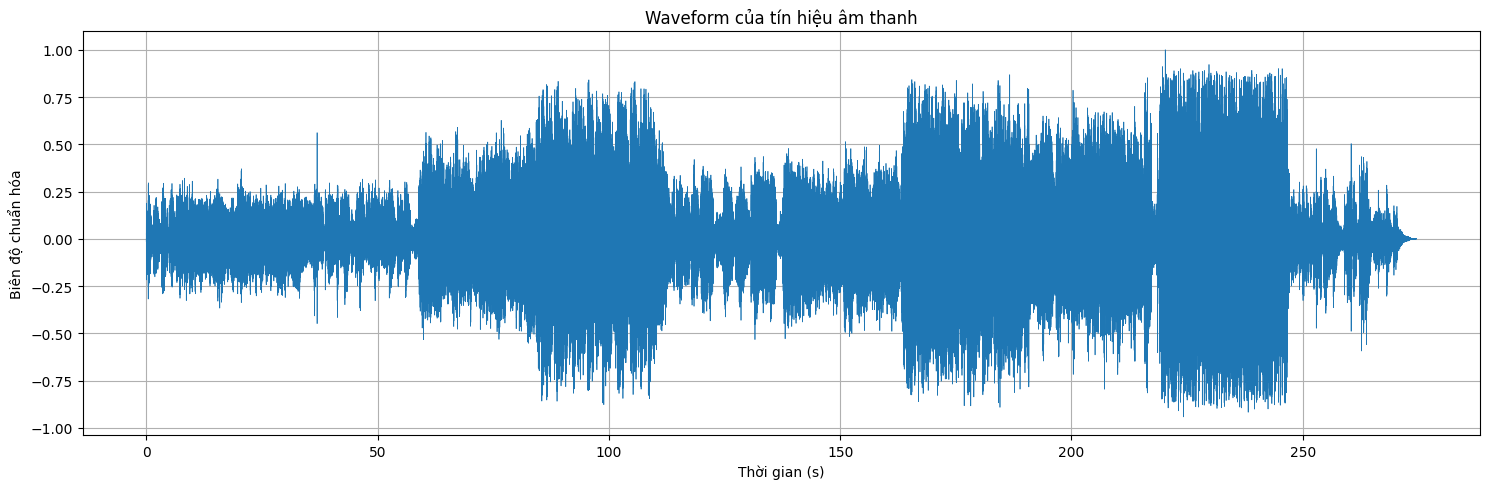

In [30]:
# %%
plt.figure(figsize=(15, 5))

plt.plot(time, audio_norm, linewidth=0.5)

plt.title("Waveform của tín hiệu âm thanh")
plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ chuẩn hóa")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "waveform_full.png"),
    dpi=300
)

plt.show()

CELL 11 — Peak, RMS, Energy

In [31]:
# %%
peak = np.max(np.abs(audio_norm))

rms = np.sqrt(np.mean(audio_norm ** 2))

energy = np.sum(audio_norm ** 2)

print("========== TIME DOMAIN ==========")
print(f"Peak   = {peak:.6f}")
print(f"RMS    = {rms:.6f}")
print(f"Energy = {energy:.6f}")

========== TIME DOMAIN ==========
Peak   = 1.000000
RMS    = 0.152898
Energy = 283090.360261


CELL 12 — Kiểm tra clipping

In [32]:
# %%
clipping_threshold = 0.999

clipped_samples = np.sum(
    np.abs(audio_norm) >= clipping_threshold
)

clipping_percentage = (
    clipped_samples / len(audio_norm) * 100
)

print("========== CLIPPING ==========")
print(f"Số mẫu clipping: {clipped_samples:,}")
print(f"Tỷ lệ clipping: {clipping_percentage:.6f}%")

========== CLIPPING ==========
Số mẫu clipping: 1
Tỷ lệ clipping: 0.000008%


CELL 13 — Chọn 2 đoạn âm thanh khác nhau

In [33]:
# %%
segment_duration = 1.0

segment_samples = int(segment_duration * fs_original)

num_segments = len(audio_norm) // segment_samples

segment_rms = []

for i in range(num_segments):

    start = i * segment_samples
    end = start + segment_samples

    segment = audio_norm[start:end]

    segment_rms.append(
        np.sqrt(np.mean(segment ** 2))
    )

segment_rms = np.array(segment_rms)

low_index = np.argmin(segment_rms)
high_index = np.argmax(segment_rms)

low_start = low_index * segment_duration
high_start = high_index * segment_duration

print("========== SELECTED SEGMENTS ==========")
print(f"Low RMS segment : {low_start:.2f} s")
print(f"High RMS segment: {high_start:.2f} s")
print(f"Low RMS value   : {segment_rms[low_index]:.6f}")
print(f"High RMS value  : {segment_rms[high_index]:.6f}")

========== SELECTED SEGMENTS ==========
Low RMS segment : 273.00 s
High RMS segment: 220.00 s
Low RMS value   : 0.001210
High RMS value  : 0.298228


CELL 14 — Vẽ 2 đoạn

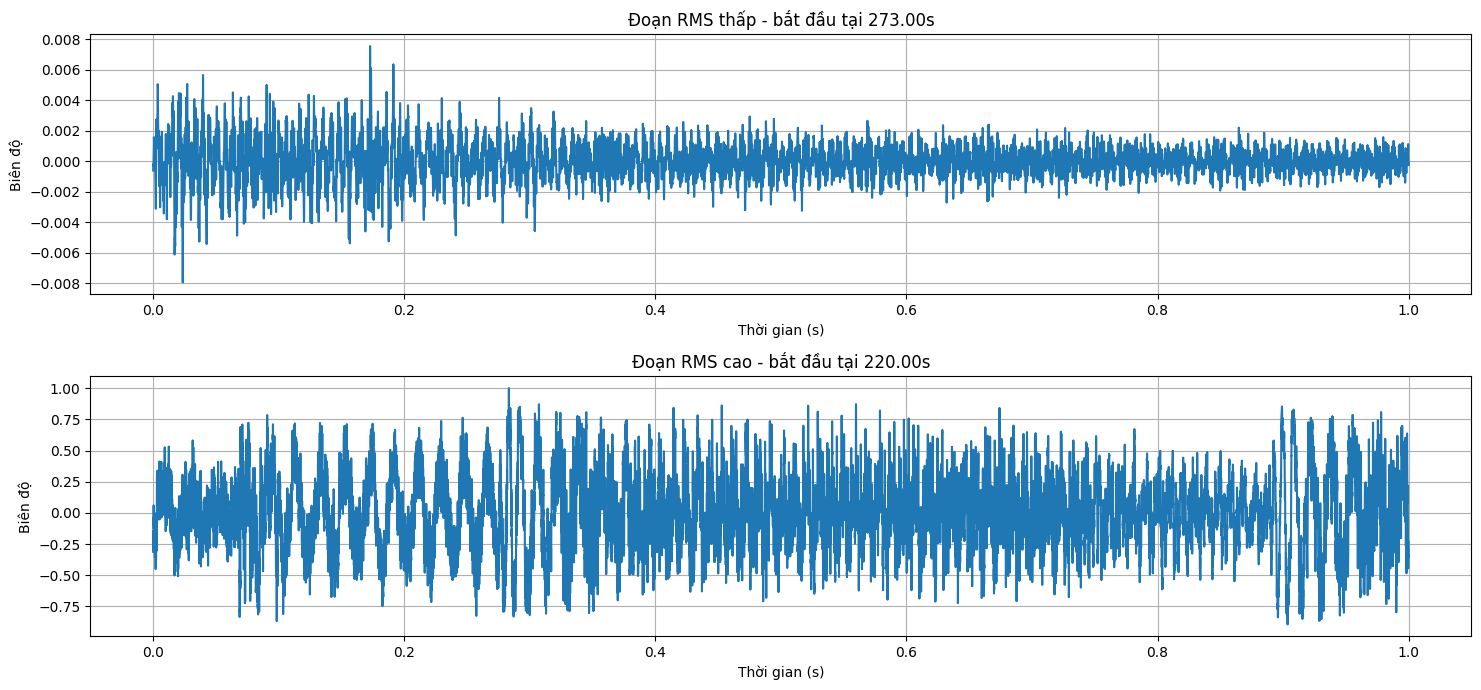

In [34]:
# %%
low_start_sample = int(low_start * fs_original)
high_start_sample = int(high_start * fs_original)

low_segment = audio_norm[
    low_start_sample:
    low_start_sample + segment_samples
]

high_segment = audio_norm[
    high_start_sample:
    high_start_sample + segment_samples
]

t_segment = np.arange(segment_samples) / fs_original

plt.figure(figsize=(15, 7))

plt.subplot(2, 1, 1)

plt.plot(t_segment, low_segment)

plt.title(
    f"Đoạn RMS thấp - bắt đầu tại {low_start:.2f}s"
)

plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ")
plt.grid(True)

plt.subplot(2, 1, 2)

plt.plot(t_segment, high_segment)

plt.title(
    f"Đoạn RMS cao - bắt đầu tại {high_start:.2f}s"
)

plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ")
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "waveform_segments.png"),
    dpi=300
)

plt.show()

CELL 15 — FFT

In [35]:
# %%
fft_segment = high_segment.copy()

def calculate_fft(x, fs, nfft):

    # Window Hamming
    window = np.hamming(len(x))

    x_windowed = x * window

    spectrum = np.fft.rfft(
        x_windowed,
        n=nfft
    )

    magnitude = np.abs(spectrum)

    frequency = np.fft.rfftfreq(
        nfft,
        d=1/fs
    )

    return frequency, magnitude


freq_2048, mag_2048 = calculate_fft(
    fft_segment,
    fs_original,
    2048
)

freq_8192, mag_8192 = calculate_fft(
    fft_segment,
    fs_original,
    8192
)

print("========== FFT ==========")
print(f"NFFT = 2048")
print(f"Δf = {fs_original / 2048:.3f} Hz")

print()

print(f"NFFT = 8192")
print(f"Δf = {fs_original / 8192:.3f} Hz")

========== FFT ==========
NFFT = 2048
Δf = 21.533 Hz

NFFT = 8192
Δf = 5.383 Hz


CELL 16 — Vẽ FFT

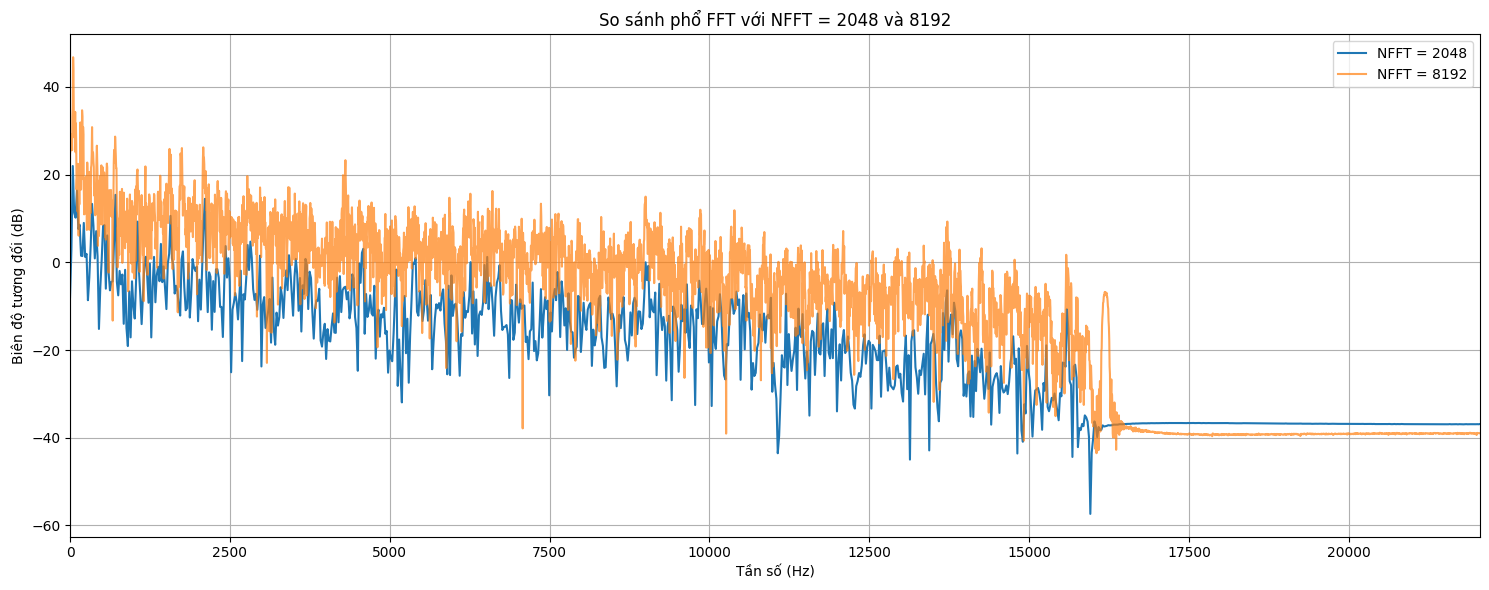

In [36]:
# %%
plt.figure(figsize=(15, 6))

plt.plot(
    freq_2048,
    20 * np.log10(mag_2048 + 1e-12),
    label="NFFT = 2048"
)

plt.plot(
    freq_8192,
    20 * np.log10(mag_8192 + 1e-12),
    alpha=0.7,
    label="NFFT = 8192"
)

plt.title("So sánh phổ FFT với NFFT = 2048 và 8192")

plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ tương đối (dB)")

plt.xlim(0, fs_original / 2)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "fft_comparison.png"),
    dpi=300
)

plt.show()

CELL 17 — Tìm 3 peak lớn nhất

# %%
# Bỏ vùng DC
valid = freq_8192 > 20

freq_valid = freq_8192[valid]
mag_valid = mag_8192[valid]

# Tìm các peak
peaks, properties = signal.find_peaks(
    mag_valid,
    distance=20
)

# Sắp xếp peak theo biên độ
sorted_peaks = peaks[
    np.argsort(
        mag_valid[peaks]
    )[::-1]
]

top_n = min(3, len(sorted_peaks))

print("========== TOP FREQUENCY PEAKS ==========")

for i in range(top_n):

    index = sorted_peaks[i]

    print(
        f"Peak {i+1}: "
        f"{freq_valid[index]:.2f} Hz"
    )

CELL 18 — STFT 10 ms

In [37]:
# %%
def compute_stft(
    x,
    fs,
    frame_ms,
    hop_ms=10
):

    nperseg = int(
        fs * frame_ms / 1000
    )

    noverlap = nperseg - int(
        fs * hop_ms / 1000
    )

    frequencies, times, Zxx = signal.stft(
        x,
        fs=fs,
        window="hamming",
        nperseg=nperseg,
        noverlap=noverlap,
        boundary=None
    )

    magnitude_db = (
        20 * np.log10(
            np.abs(Zxx) + 1e-10
        )
    )

    return frequencies, times, magnitude_db

CELL 19 — STFT 10 ms

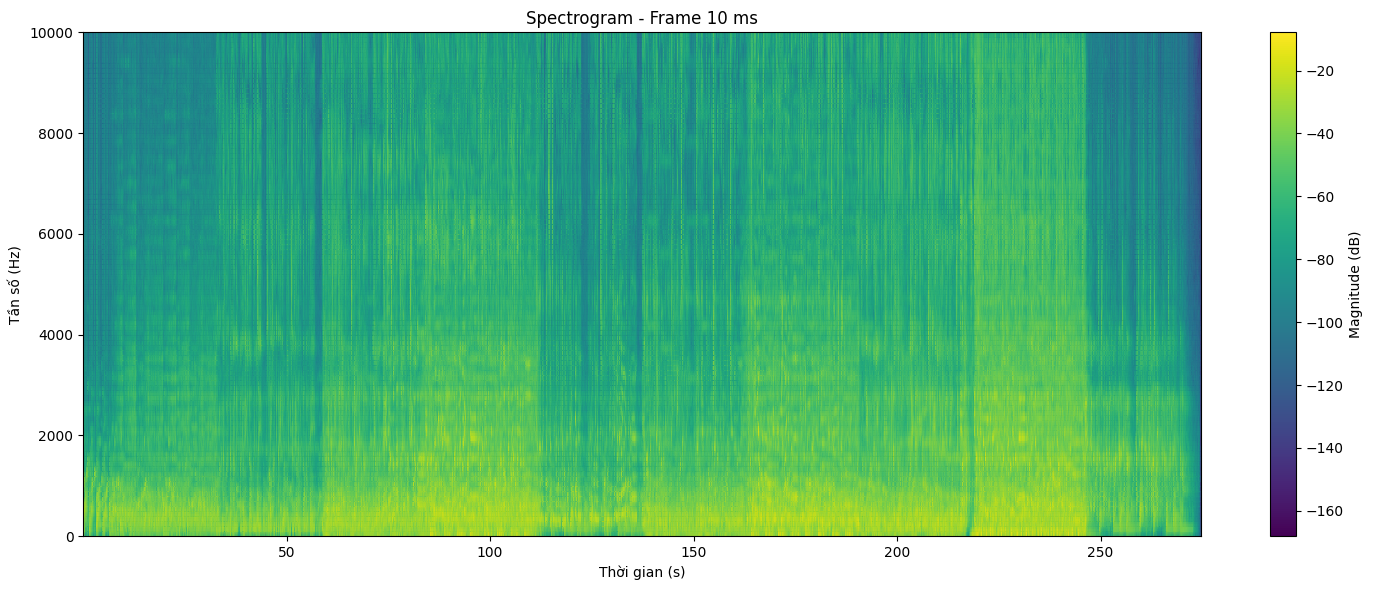

In [38]:
# %%
f10, t10, S10 = compute_stft(
    audio_norm,
    fs_original,
    frame_ms=10,
    hop_ms=10
)

plt.figure(figsize=(15, 6))

plt.pcolormesh(
    t10,
    f10,
    S10,
    shading="gouraud"
)

plt.title("Spectrogram - Frame 10 ms")

plt.xlabel("Thời gian (s)")
plt.ylabel("Tần số (Hz)")

plt.ylim(0, 10000)

plt.colorbar(
    label="Magnitude (dB)"
)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "spectrogram_10ms.png"),
    dpi=300
)

plt.show()

CELL 20 — STFT 25 ms

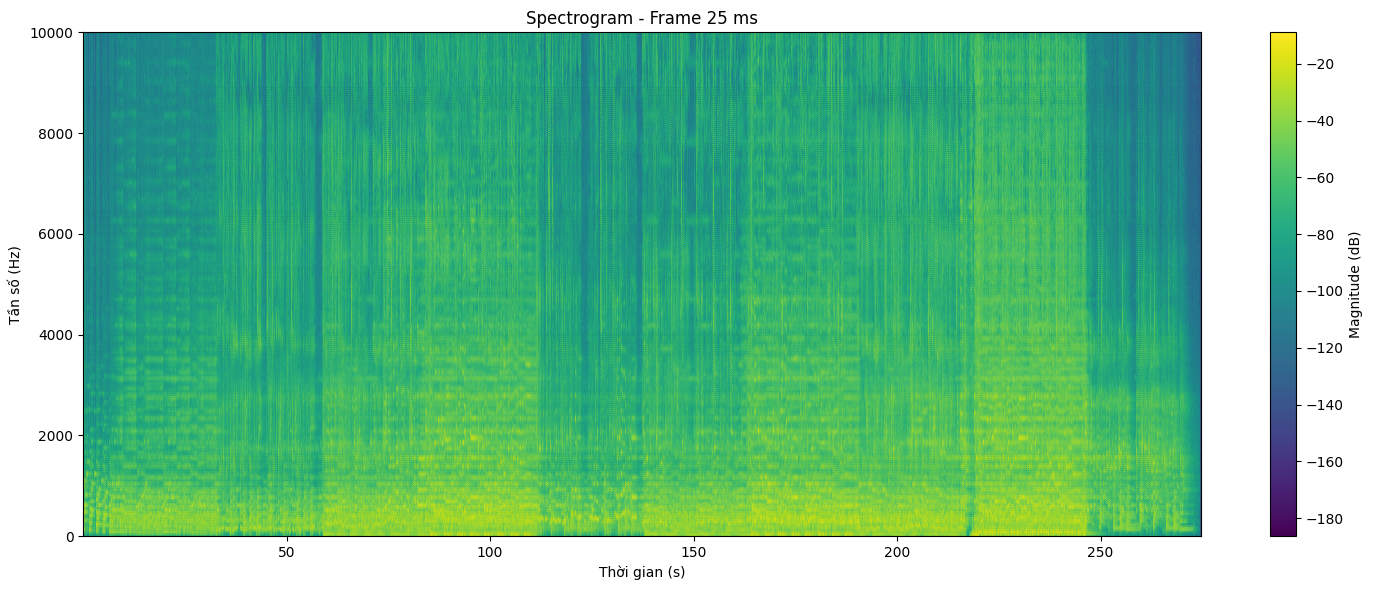

In [39]:
# %%
f25, t25, S25 = compute_stft(
    audio_norm,
    fs_original,
    frame_ms=25,
    hop_ms=10
)

plt.figure(figsize=(15, 6))

plt.pcolormesh(
    t25,
    f25,
    S25,
    shading="gouraud"
)

plt.title("Spectrogram - Frame 25 ms")

plt.xlabel("Thời gian (s)")
plt.ylabel("Tần số (Hz)")

plt.ylim(0, 10000)

plt.colorbar(
    label="Magnitude (dB)"
)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "spectrogram_25ms.png"),
    dpi=300
)

plt.show()

CELL 21 — STFT 50 ms

In [75]:
# %%
# ==========================================
# STFT - FRAME 50 ms
# Chỉ sử dụng 30 giây đầu để tránh MemoryError
# ==========================================

MAX_DURATION = 30  # giây

max_samples = int(
    MAX_DURATION * fs_original
)

audio_for_stft = audio_norm[:max_samples]

print("STFT được tính trên:")
print(f"- Thời lượng: {MAX_DURATION} giây")
print(f"- Số mẫu: {len(audio_for_stft):,}")

# Tính STFT
f50, t50, S50 = compute_stft(
    audio_for_stft,
    fs_original,
    frame_ms=50,
    hop_ms=10
)

print("Kích thước spectrogram:")
print("Frequency bins:", len(f50))
print("Time frames:", len(t50))

STFT được tính trên:
- Thời lượng: 30 giây
- Số mẫu: 1,323,000
Kích thước spectrogram:
Frequency bins: 1103
Time frames: 2996


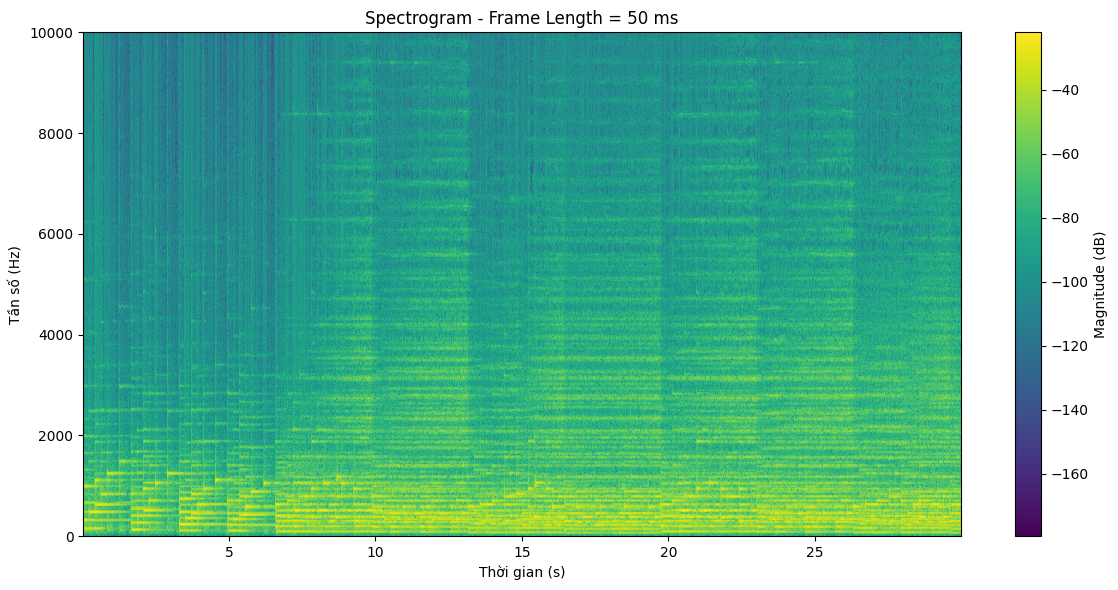

In [76]:
# %%
# ==========================================
# VẼ SPECTROGRAM - FRAME 50 ms
# ==========================================

plt.close("all")

fig, ax = plt.subplots(
    figsize=(12, 6)
)

mesh = ax.pcolormesh(
    t50,
    f50,
    S50,
    shading="auto"
)

ax.set_title(
    "Spectrogram - Frame Length = 50 ms"
)

ax.set_xlabel(
    "Thời gian (s)"
)

ax.set_ylabel(
    "Tần số (Hz)"
)

# Chỉ hiển thị vùng tần số phù hợp
ax.set_ylim(
    0,
    10000
)

fig.colorbar(
    mesh,
    ax=ax,
    label="Magnitude (dB)"
)

fig.tight_layout()

fig.savefig(
    os.path.join(
        FIGURE_DIR,
        "spectrogram_50ms.png"
    ),
    dpi=200
)

plt.show()

plt.close(fig)

CELL 22 — So sánh Rectangular và Hamming

In [43]:
# %%
# Lấy một frame 25 ms
frame_ms = 25

frame_length = int(
    fs_original * frame_ms / 1000
)

frame = audio_norm[
    high_start_sample:
    high_start_sample + frame_length
]

nfft = 8192

# Rectangular
window_rect = np.ones(
    len(frame)
)

# Hamming
window_hamming = np.hamming(
    len(frame)
)

fft_rect = np.fft.rfft(
    frame * window_rect,
    n=nfft
)

fft_hamming = np.fft.rfft(
    frame * window_hamming,
    n=nfft
)

freq_window = np.fft.rfftfreq(
    nfft,
    1 / fs_original
)

CELL 23 — Vẽ Window comparison

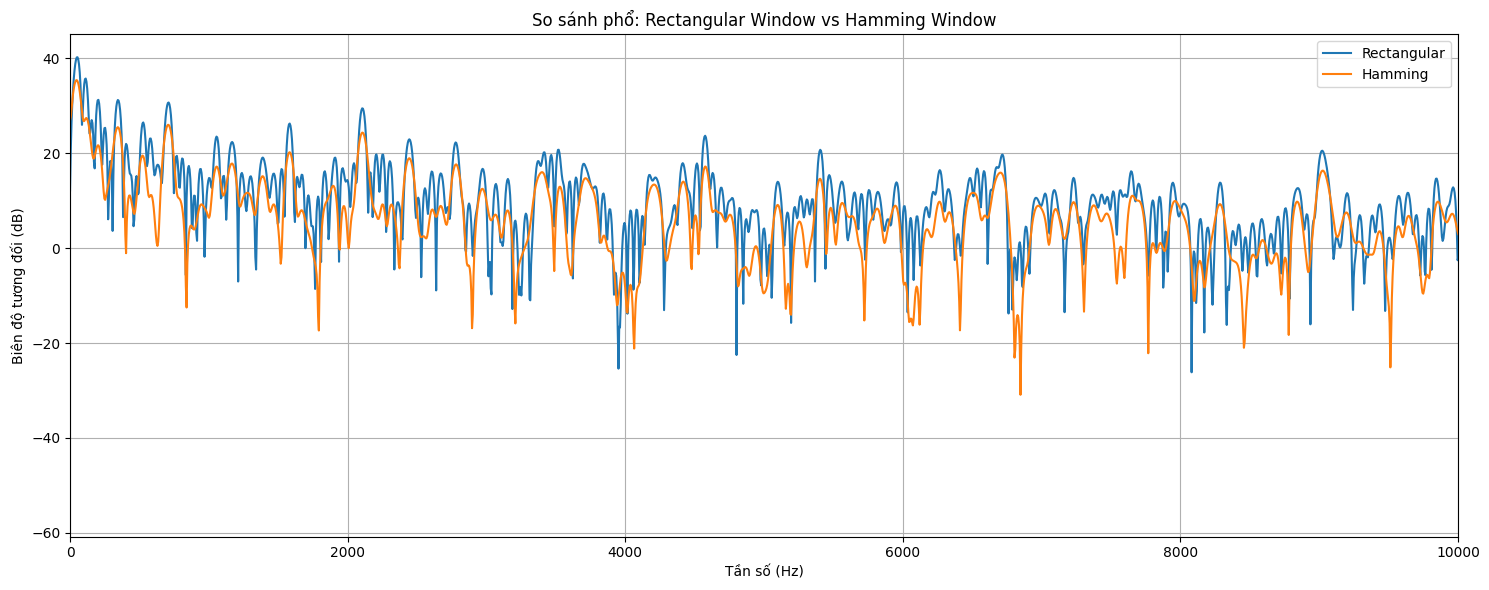

In [44]:
# %%
plt.figure(figsize=(15, 6))

plt.plot(
    freq_window,
    20 * np.log10(
        np.abs(fft_rect) + 1e-12
    ),
    label="Rectangular"
)

plt.plot(
    freq_window,
    20 * np.log10(
        np.abs(fft_hamming) + 1e-12
    ),
    label="Hamming"
)

plt.xlim(0, 10000)

plt.title(
    "So sánh phổ: Rectangular Window vs Hamming Window"
)

plt.xlabel("Tần số (Hz)")
plt.ylabel("Biên độ tương đối (dB)")

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "window_comparison.png"
    ),
    dpi=300
)

plt.show()

CELL 24 — Thiết kế FIR Low-pass

In [45]:
# %%
FILTER_ORDER = 200
NUM_TAPS = FILTER_ORDER + 1

LOWPASS_CUTOFF = 3000

lowpass_coeff = signal.firwin(
    NUM_TAPS,
    cutoff=LOWPASS_CUTOFF,
    fs=fs_original,
    window="hamming",
    pass_zero="lowpass"
)

print("========== LOW-PASS FIR ==========")
print(f"Number of taps: {NUM_TAPS}")
print(f"Cutoff: {LOWPASS_CUTOFF} Hz")
print(
    f"Group delay: "
    f"{FILTER_ORDER / 2:.0f} samples"
)
print(
    f"Group delay: "
    f"{FILTER_ORDER / 2 / fs_original * 1000:.3f} ms"
)

========== LOW-PASS FIR ==========
Number of taps: 201
Cutoff: 3000 Hz
Group delay: 100 samples
Group delay: 2.268 ms


CELL 25 — Thiết kế FIR High-pass

In [46]:
# %%
HIGHPASS_CUTOFF = 3000

highpass_coeff = signal.firwin(
    NUM_TAPS,
    cutoff=HIGHPASS_CUTOFF,
    fs=fs_original,
    window="hamming",
    pass_zero="highpass"
)

print("========== HIGH-PASS FIR ==========")
print(f"Number of taps: {NUM_TAPS}")
print(f"Cutoff: {HIGHPASS_CUTOFF} Hz")

========== HIGH-PASS FIR ==========
Number of taps: 201
Cutoff: 3000 Hz


CELL 26 — Frequency response của FIR

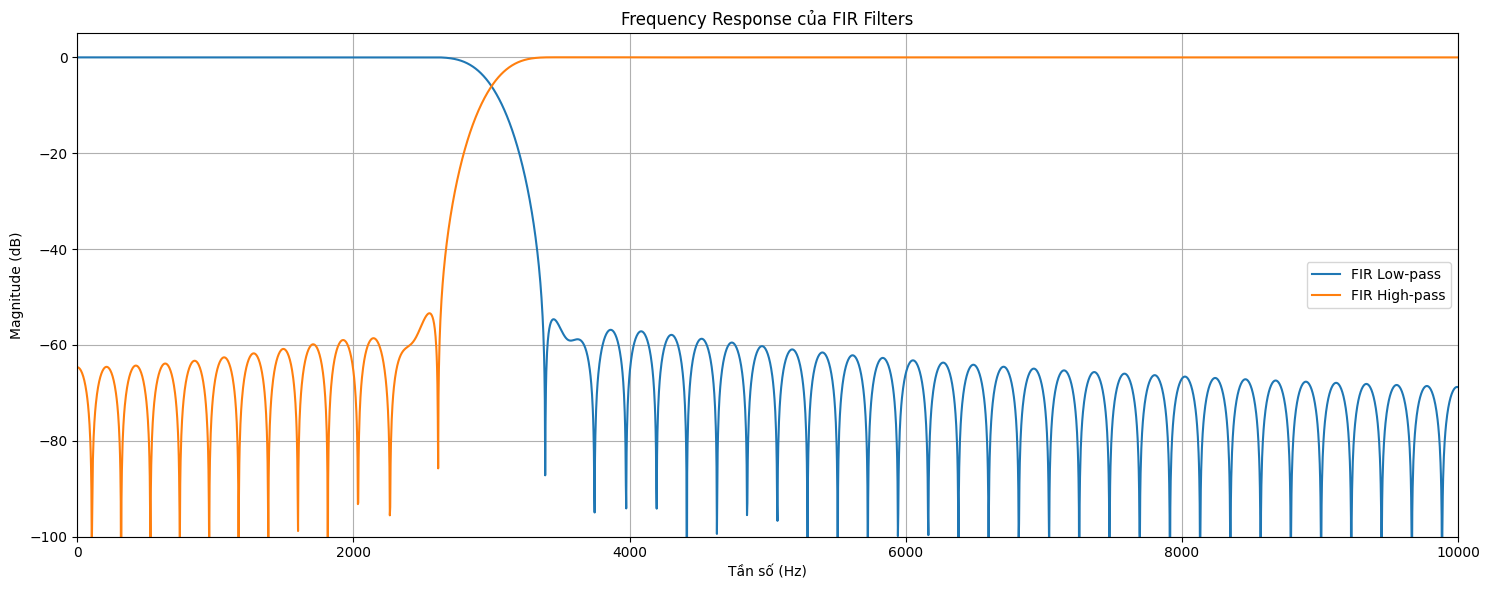

In [47]:
# %%
w_lp, h_lp = signal.freqz(
    lowpass_coeff,
    worN=8192,
    fs=fs_original
)

w_hp, h_hp = signal.freqz(
    highpass_coeff,
    worN=8192,
    fs=fs_original
)

plt.figure(figsize=(15, 6))

plt.plot(
    w_lp,
    20 * np.log10(
        np.abs(h_lp) + 1e-12
    ),
    label="FIR Low-pass"
)

plt.plot(
    w_hp,
    20 * np.log10(
        np.abs(h_hp) + 1e-12
    ),
    label="FIR High-pass"
)

plt.title("Frequency Response của FIR Filters")

plt.xlabel("Tần số (Hz)")
plt.ylabel("Magnitude (dB)")

plt.xlim(0, 10000)

plt.ylim(-100, 5)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "filter_response.png"
    ),
    dpi=300
)

plt.show()

CELL 27 — Áp dụng Low-pass

In [48]:
# %%
filtered_lowpass = signal.lfilter(
    lowpass_coeff,
    1.0,
    audio_norm
)

print("Đã áp dụng Low-pass filter.")

Đã áp dụng Low-pass filter.


CELL 28 — Áp dụng High-pass

In [49]:
# %%
filtered_highpass = signal.lfilter(
    highpass_coeff,
    1.0,
    audio_norm
)

print("Đã áp dụng High-pass filter.")

Đã áp dụng High-pass filter.


CELL 29 — Hàm lưu WAV

In [51]:
# %%
def save_wav(
    filename,
    audio_data,
    fs
):

    # Giới hạn biên độ
    audio_data = np.clip(
        audio_data,
        -1,
        1
    )

    # Chuyển float [-1,1]
    # thành int16
    audio_int16 = (
        audio_data * 32767
    ).astype(np.int16)

    wavfile.write(
        filename,
        fs,
        audio_int16
    )

CELL 30 — Lưu audio sau filtering

In [53]:
# %%
save_wav(
    os.path.join(
        AUDIO_DIR,
        "filtered_lowpass.wav"
    ),
    filtered_lowpass,
    fs_original
)

save_wav(
    os.path.join(
        AUDIO_DIR,
        "filtered_highpass.wav"
    ),
    filtered_highpass,
    fs_original
)

print("Đã xuất:")
print("- filtered_lowpass.wav")
print("- filtered_highpass.wav")

Đã xuất:
- filtered_lowpass.wav
- filtered_highpass.wav


CELL 31 — So sánh spectrum trước và sau lọc

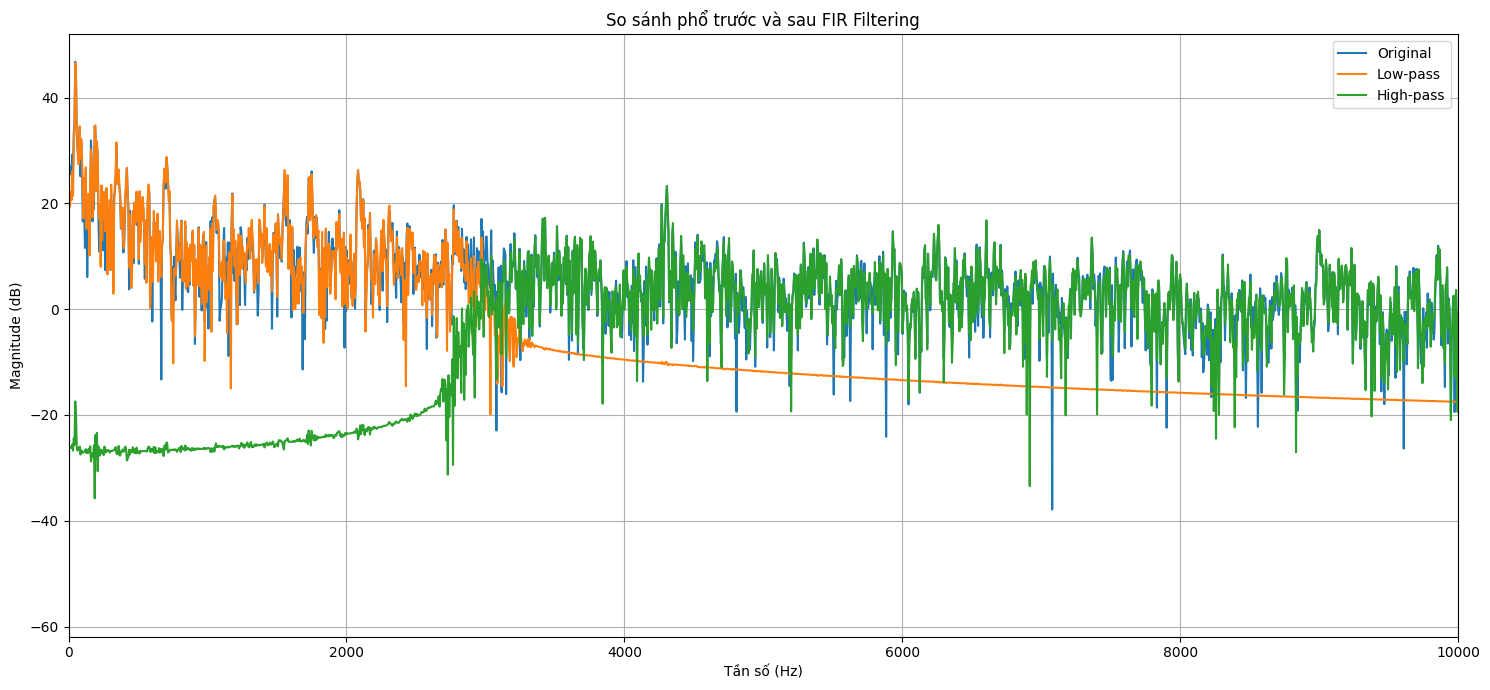

In [54]:
# %%
compare_duration = 1.0

compare_samples = int(
    compare_duration * fs_original
)

original_compare = audio_norm[
    high_start_sample:
    high_start_sample + compare_samples
]

low_compare = filtered_lowpass[
    high_start_sample:
    high_start_sample + compare_samples
]

high_compare = filtered_highpass[
    high_start_sample:
    high_start_sample + compare_samples
]

nfft = 8192

f_original, m_original = calculate_fft(
    original_compare,
    fs_original,
    nfft
)

f_low, m_low = calculate_fft(
    low_compare,
    fs_original,
    nfft
)

f_high, m_high = calculate_fft(
    high_compare,
    fs_original,
    nfft
)

plt.figure(figsize=(15, 7))

plt.plot(
    f_original,
    20 * np.log10(
        m_original + 1e-12
    ),
    label="Original"
)

plt.plot(
    f_low,
    20 * np.log10(
        m_low + 1e-12
    ),
    label="Low-pass"
)

plt.plot(
    f_high,
    20 * np.log10(
        m_high + 1e-12
    ),
    label="High-pass"
)

plt.xlim(0, 10000)

plt.title(
    "So sánh phổ trước và sau FIR Filtering"
)

plt.xlabel("Tần số (Hz)")
plt.ylabel("Magnitude (dB)")

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "filter_spectrum.png"
    ),
    dpi=300
)

plt.show()

CELL 32 — Quantization

In [55]:
# %%
def quantize_signal(
    x,
    bits
):

    levels = 2 ** bits

    delta = 2 / levels

    # Lượng tử hóa
    q = np.round(
        x / delta
    ) * delta

    # Giới hạn
    q = np.clip(
        q,
        -1,
        1
    )

    return q

CELL 33 — Hàm tính SNR

In [56]:
# %%
def calculate_snr(
    original,
    quantized
):

    error = (
        quantized - original
    )

    signal_power = np.sum(
        original ** 2
    )

    error_power = np.sum(
        error ** 2
    )

    if error_power == 0:
        return np.inf

    snr = 10 * np.log10(
        signal_power / error_power
    )

    return snr

CELL 34 — Quantization 4/8/16 bit

In [57]:
# %%
quantization_results = []

quantized_signals = {}

for bits in [4, 8, 16]:

    quantized = quantize_signal(
        audio_norm,
        bits
    )

    snr_value = calculate_snr(
        audio_norm,
        quantized
    )

    quantized_signals[bits] = quantized

    quantization_results.append({
        "Bits": bits,
        "SNR_dB": snr_value
    })

    print(
        f"{bits}-bit: "
        f"SNR = {snr_value:.3f} dB"
    )

4-bit: SNR = 12.805 dB
8-bit: SNR = 36.645 dB
16-bit: SNR = 84.791 dB


CELL 35 — Lưu các file quantized

In [58]:
# %%
for bits in [4, 8, 16]:

    filename = os.path.join(
        AUDIO_DIR,
        f"quantized_{bits}bit.wav"
    )

    save_wav(
        filename,
        quantized_signals[bits],
        fs_original
    )

print("Đã lưu các file quantized.")

Đã lưu các file quantized.


CELL 36 — Vẽ SNR

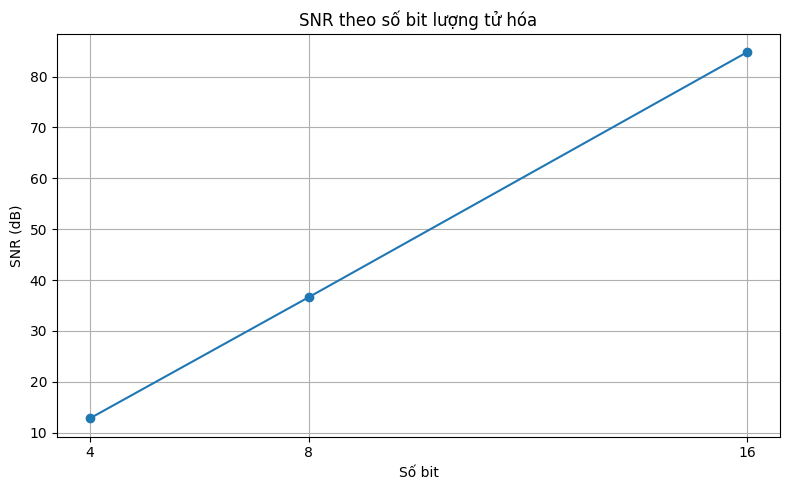

,Bits,SNR_dB
0,4,12.805170
1,8,36.644961
2,16,84.791291


In [59]:
# %%
snr_df = pd.DataFrame(
    quantization_results
)

plt.figure(figsize=(8, 5))

plt.plot(
    snr_df["Bits"],
    snr_df["SNR_dB"],
    marker="o"
)

plt.title(
    "SNR theo số bit lượng tử hóa"
)

plt.xlabel("Số bit")

plt.ylabel("SNR (dB)")

plt.xticks([4, 8, 16])

plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "quantization_snr.png"
    ),
    dpi=300
)

plt.show()

snr_df

CELL 37 — Resampling xuống 16 kHz và 8 kHz

In [60]:
# %%
def resample_audio(
    x,
    original_fs,
    target_fs
):

    gcd = np.gcd(
        original_fs,
        target_fs
    )

    up = target_fs // gcd
    down = original_fs // gcd

    y = signal.resample_poly(
        x,
        up,
        down
    )

    return y

CELL 38 — Resample 16k

In [61]:
# %%
audio_16k = resample_audio(
    audio_norm,
    fs_original,
    16000
)

print("16 kHz")
print("Số mẫu:", len(audio_16k))
print(
    "Duration:",
    len(audio_16k) / 16000,
    "seconds"
)

16 kHz
Số mẫu: 4393425
Duration: 274.5890625 seconds


CELL 39 — Resample 8k

In [62]:
# %%
audio_8k = resample_audio(
    audio_norm,
    fs_original,
    8000
)

print("8 kHz")
print("Số mẫu:", len(audio_8k))
print(
    "Duration:",
    len(audio_8k) / 8000,
    "seconds"
)

8 kHz
Số mẫu: 2196713
Duration: 274.589125 seconds


CELL 40 — Lưu resampled audio

In [63]:
# %%
save_wav(
    os.path.join(
        AUDIO_DIR,
        "resampled_16k.wav"
    ),
    audio_16k,
    16000
)

save_wav(
    os.path.join(
        AUDIO_DIR,
        "resampled_8k.wav"
    ),
    audio_8k,
    8000
)

print("Đã lưu:")
print("- resampled_16k.wav")
print("- resampled_8k.wav")

Đã lưu:
- resampled_16k.wav
- resampled_8k.wav


CELL 41 — Spectrum của 44.1k / 16k / 8k

In [64]:
# %%
def spectrum(
    x,
    fs,
    nfft=8192
):

    window = np.hamming(
        len(x)
    )

    X = np.fft.rfft(
        x * window,
        n=nfft
    )

    f = np.fft.rfftfreq(
        nfft,
        1 / fs
    )

    magnitude = 20 * np.log10(
        np.abs(X) + 1e-12
    )

    return f, magnitude


# Lấy 1 đoạn ngắn
duration_compare = 1

segment_original = audio_norm[
    high_start_sample:
    high_start_sample +
    int(fs_original * duration_compare)
]

segment_16k = audio_16k[
    high_start_sample * 16000 // fs_original:
    high_start_sample * 16000 // fs_original + 16000
]

segment_8k = audio_8k[
    high_start_sample * 8000 // fs_original:
    high_start_sample * 8000 // fs_original + 8000
]

f_orig, s_orig = spectrum(
    segment_original,
    fs_original
)

f_16, s_16 = spectrum(
    segment_16k,
    16000
)

f_8, s_8 = spectrum(
    segment_8k,
    8000
)

CELL 42 — Vẽ spectrum resampling

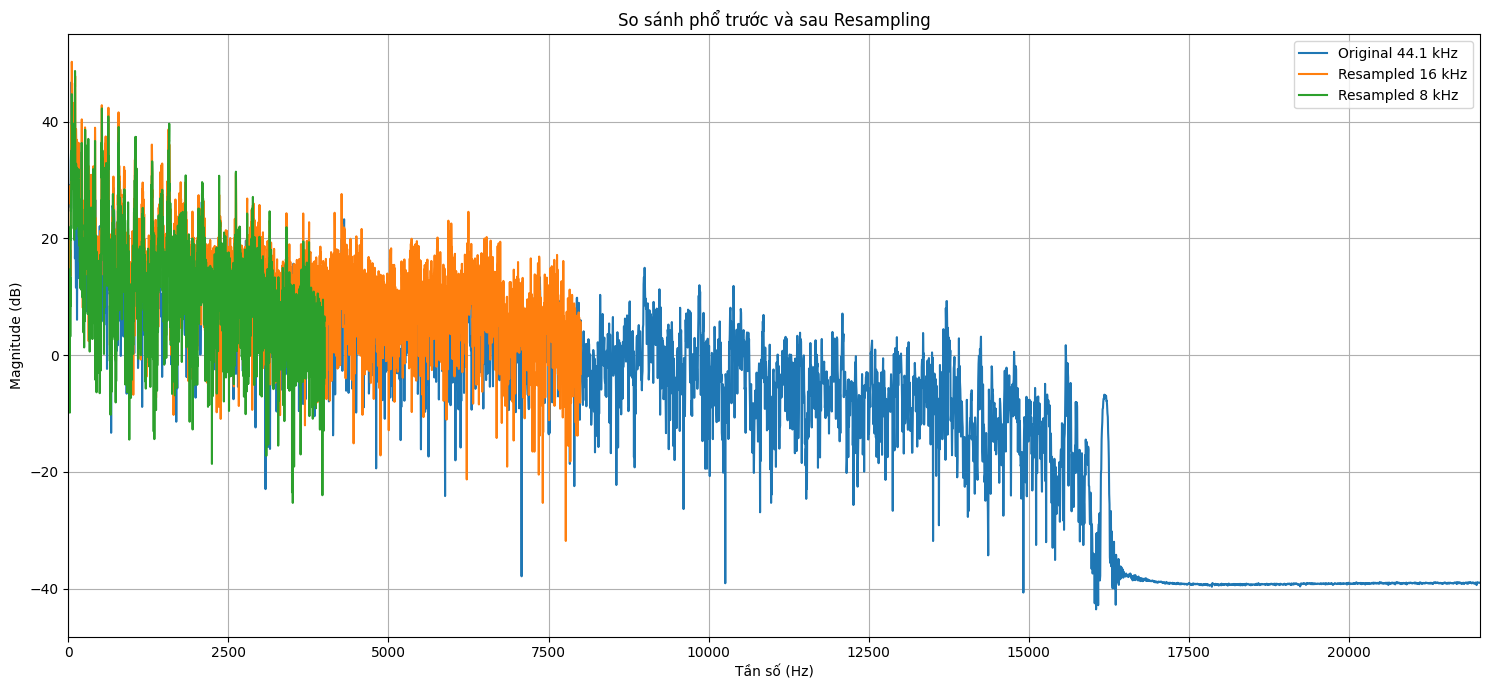

In [65]:
# %%
plt.figure(figsize=(15, 7))

plt.plot(
    f_orig,
    s_orig,
    label="Original 44.1 kHz"
)

plt.plot(
    f_16,
    s_16,
    label="Resampled 16 kHz"
)

plt.plot(
    f_8,
    s_8,
    label="Resampled 8 kHz"
)

plt.title(
    "So sánh phổ trước và sau Resampling"
)

plt.xlabel("Tần số (Hz)")
plt.ylabel("Magnitude (dB)")

plt.xlim(0, 22050)

plt.grid(True)
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "resampling_spectrum.png"
    ),
    dpi=300
)

plt.show()

CELL 43 — PCM bitrate

In [66]:
# %%
pcm_bitrate = (
    fs_original *
    bit_depth_original *
    channels_original
)

pcm_bitrate_kbps = (
    pcm_bitrate / 1000
)

pcm_size_bytes = (
    pcm_bitrate *
    duration / 8
)

pcm_size_mb = (
    pcm_size_bytes /
    (1024 ** 2)
)

print("========== PCM ==========")
print(
    f"PCM bitrate: "
    f"{pcm_bitrate_kbps:.2f} kbps"
)

print(
    f"PCM theoretical size: "
    f"{pcm_size_mb:.2f} MB"
)

========== PCM ==========
PCM bitrate: 1411.20 kbps
PCM theoretical size: 46.19 MB


CELL 44 — Compression ratio

In [67]:
# %%
compression_ratio = (
    pcm_size_bytes /
    file_size_bytes
)

saving_percentage = (
    1 -
    file_size_bytes /
    pcm_size_bytes
) * 100

print("========== COMPRESSION ==========")

print(
    f"Original MP3 size: "
    f"{file_size_bytes / (1024**2):.2f} MB"
)

print(
    f"Theoretical PCM size: "
    f"{pcm_size_mb:.2f} MB"
)

print(
    f"Compression ratio: "
    f"{compression_ratio:.2f}:1"
)

print(
    f"Size saving: "
    f"{saving_percentage:.2f}%"
)

print(
    f"Estimated MP3 average bitrate: "
    f"{estimated_bitrate_kbps:.2f} kbps"
)

========== COMPRESSION ==========
Original MP3 size: 4.42 MB
Theoretical PCM size: 46.19 MB
Compression ratio: 10.45:1
Size saving: 90.43%
Estimated MP3 average bitrate: 135.08 kbps


CELL 45 — Tổng hợp bảng kết quả

In [73]:
# %%
summary = pd.DataFrame({
    "Parameter": [
        "File",
        "Duration (s)",
        "Sample Rate (Hz)",
        "Channels",
        "Bit Depth (bits)",
        "File Size (MB)",
        "Estimated Bitrate (kbps)",
        "Peak",
        "RMS",
        "Energy",
        "Clipping (%)",
        "PCM Bitrate (kbps)",
        "PCM Size (MB)",
        "Compression Ratio",
        "Saving (%)"
    ],

    "Value": [
        INPUT_FILE,
        duration,
        fs_original,
        channels_original,
        bit_depth_original,
        file_size_bytes / (1024**2),
        estimated_bitrate_kbps,
        peak,
        rms,
        energy,
        clipping_percentage,
        pcm_bitrate_kbps,
        pcm_size_mb,
        compression_ratio,
        saving_percentage
    ]
})

summary

,Parameter,Value
0,File,input.mp3
1,Duration (s),274.589048
2,Sample Rate (Hz),44100
3,Channels,2
4,Bit Depth (bits),16
5,File Size (MB),4.421547
6,Estimated Bitrate (kbps),135.076851
7,Peak,1.0
8,RMS,0.152898
9,Energy,283090.360261


CELL 46 — Lưu summary.csv

In [74]:
# %%
summary_path = os.path.join(
    RESULT_DIR,
    "summary.csv"
)

summary.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Đã lưu kết quả tại: "
    f"{summary_path}"
)

Đã lưu kết quả tại: results\summary.csv


CELL 47 — Lưu bảng Quantization

In [71]:
# %%
quantization_path = os.path.join(
    RESULT_DIR,
    "quantization_results.csv"
)

snr_df.to_csv(
    quantization_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    f"Đã lưu: {quantization_path}"
)

Đã lưu: results\quantization_results.csv


CELL 48 — Kiểm tra toàn bộ output

In [72]:
# %%
print("=" * 60)
print("KIỂM TRA KẾT QUẢ LAB 1")
print("=" * 60)

print("\n[AUDIO]")
for filename in os.listdir(AUDIO_DIR):
    print("✓", filename)

print("\n[FIGURES]")
for filename in os.listdir(FIGURE_DIR):
    print("✓", filename)

print("\n[RESULTS]")
for filename in os.listdir(RESULT_DIR):
    print("✓", filename)

print("\nLab 1 đã chạy hoàn tất.")

KIỂM TRA KẾT QUẢ LAB 1

[AUDIO]
✓ filtered_highpass.wav
✓ filtered_lowpass.wav
✓ quantized_16bit.wav
✓ quantized_4bit.wav
✓ quantized_8bit.wav
✓ resampled_16k.wav
✓ resampled_8k.wav

[FIGURES]
✓ fft_comparison.png
✓ filter_response.png
✓ filter_spectrum.png
✓ quantization_snr.png
✓ resampling_spectrum.png
✓ spectrogram_10ms.png
✓ spectrogram_25ms.png
✓ waveform_full.png
✓ waveform_segments.png
✓ window_comparison.png

[RESULTS]
✓ quantization_results.csv
✓ summary.csv

Lab 1 đã chạy hoàn tất.
